# Network Gene Usage

**Question.** What does the network do with the genes? How much does it move the cure probability of each patient, which genes drive it, and how does it organize the patients?

**Scope.** One fixed model: Structure 3 of the project (log-normal) fitted on all 1,849 patients, with the weights saved by `Final analysis.ipynb`. Every result is reported on all patients. The notebook describes the fitted function.

**Limits.**
- It describes the fitted function. `Gene Added Value.ipynb` shows that adding the genes does not improve the prediction of new patients, so nothing here is a claim about biology.
    - Intervals and Shapley values depend on this single fit, and the effects of rare genes rest on a handful of patients.

```
S(t | x) = p + (1 - p) S1(t),    z = (log t - mu) / sigma
mu       = z_mu · beta_mu                   linear in age, NPI, PAM50
sigma    = exp(z_sigma · beta_sigma)        linear in PAM50
logit(p) = z_p · beta_p + NN(genes)         linear in age, NPI, PAM50, plus a network on the 173 gene counts
```

`NN(genes)` is called `p_nn`. A positive `p_nn` raises the cure odds and a negative one lowers them.

Sections:

1. Predictions with and without the genes, under two definitions of "without".
2. Shapley values of `p_nn`.
3. t-SNE of the patients with a significant gene effect.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from IPython.display import display
from tqdm.auto import tqdm

from scipy.stats import norm, spearmanr
from scipy.special import expit, logit
from sklearn.manifold import TSNE
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold
import lifelines
from lifelines.utils import concordance_index

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import thetaflow as thf

sys.path.insert(0, "../src")
from package import cure_aft, evaluation_metrics

DIST = "ln"
CACHE_DIR = Path(os.environ.get("DSA_CACHE", "../results/gene_effect"))
CACHE_DIR.mkdir(parents = True, exist_ok = True)
WEIGHTS_DIR = Path("../model_weights/Interpretability")

SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "claudin-low", "Normal"]
SUBTYPE_COLOR = dict(zip(SUBTYPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
NEG, POS, NS = "#e34948", "#2a78d6", "#b9b8b2"
DIRECTION_COLOR = {"lowers cure odds": NEG, "not significant": NS, "raises cure odds": POS}
DIVERGING = LinearSegmentedColormap.from_list("neg_pos", [NEG, "#e5e4e0", POS])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9, "legend.frameon": False,
})

/home/tonso/code/nhilariosilva/metabric_aft_models/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


I0000 00:00:1794002292.465840  864982 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794002293.080693  864982 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Data and models

In [2]:
clean = pd.concat([pd.read_csv("../data/00_clean/metabric_train_data.csv"), pd.read_csv("../data/00_clean/metabric_test_data.csv")], ignore_index = True)
df = pd.concat([pd.read_csv("../data/01_mlready/metabric_train.csv"), pd.read_csv("../data/01_mlready/metabric_test.csv")], ignore_index = True)
assert (clean["patient_id"] == df["patient_id"]).all()

y, delta, X = df["time"] / 12, df["delta"], df.iloc[:, 10:]
subtype = clean["pam50_subtype"]
z_mu = df.iloc[:, 3:10].copy()
z_mu.insert(0, "const", 1.0)
z_sigma = df.iloc[:, 5:10].copy()
z_sigma.insert(0, "const", 1.0)
z_p = df.iloc[:, 3:10].copy()
z_p1 = z_p.copy()
z_p1.insert(0, "const", 1.0)
n_mutated = (X > 0).sum(axis = 1)
print(f"{len(df)} patients ({int(delta.sum())} events), {X.shape[1]} genes, all used to fit the model")

params3, loss3, survival_cure3 = cure_aft.build_cure_aft_structure3(DIST, z_mu, z_sigma, z_p)
NN_ARCH = (cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast)
model3 = thf.ModelNN(params3, loss3, *NN_ARCH, input_dim = (X.shape[1],), seed = 10)
model3.load_model(str(WEIGHTS_DIR / f"{DIST}_model_structure3"))

params1, loss1, survival_cure1 = cure_aft.build_cure_aft_structure1(DIST, z_mu, z_sigma, z_p1)
model1 = thf.ModelNN(params1, loss1, seed = 10)
model1(None)
model1.load_model(str(WEIGHTS_DIR / f"{DIST}_model_structure1"))

def predict3(X_counts):
    """Forecast of Structure 3 for every patient, with the gene counts replaced by X_counts."""
    return survival_cure3(model3, y, delta, X, z_mu, z_sigma, z_p, y, delta, X_counts, z_mu, z_sigma, z_p, ngrid = 100)

def survival_at(summary, t):
    grid, S = summary["ts_grid"].ravel(), summary["S_ts_test"]
    return np.array([np.interp(t, grid, S[:, j]) for j in range(S.shape[1])])

WITH = predict3(X)
ZERO = predict3(X * 0)
STRUCTURE1 = survival_cure1(model1, y, delta, z_mu, z_sigma, z_p1, y, delta, z_mu, z_sigma, z_p1, ngrid = 100)
REFERENCES = {"zero-out": ZERO, "Structure 1": STRUCTURE1}

GENE = model3.summary(X).iloc[:, -4:].reset_index(drop = True)
GENE["significant"] = (GENE["p_nn_lower"] > 0) | (GENE["p_nn_upper"] < 0)
GENE["direction"] = np.where(~GENE["significant"], "not significant", np.where(GENE["p_nn"] > 0, "raises cure odds", "lowers cure odds"))
print(f"{GENE['significant'].mean():.1%} of the patients have a gene effect whose 95% interval excludes 0")

1849 patients (754 events), 173 genes, all used to fit the model


Model successfully loaded from ../model_weights/Interpretability/ln_model_structure3.
Model successfully loaded from ../model_weights/Interpretability/ln_model_structure1.


28.6% of the patients have a gene effect whose 95% interval excludes 0


## 1. Predictions with and without the genes

The same four graphs are drawn for two definitions of "without the genes".

- **Zero-out.** The fitted Structure 3 evaluated on a patient with no mutations (all gene counts set to 0). Only `p_nn` changes. Every patient carries at least one mutation, so the zero profile is never observed. Its cure level is also higher than the typical patient's, so the difference mixes the effect of the mutation burden with the baseline shift between the zero profile and a typical one.
- **Structure 1.** The forecast of the structure that has no network, fitted on the same patients with the same loss, and a constant in the cure part. The difference contains the cure effect of the genes and also the changes the fit makes to the clinical coefficients and to the timing part, so the 10-year panel is no longer a pure cure effect.

The four graphs are: the cure probability of each patient with against without the genes, the change in cure probability by subtype, the change in 10-year relapse-free probability by subtype and the change in cure probability against the number of mutated genes. Colors in the last graph give the direction of the gene effect (gray: the 95% interval of `p_nn` contains 0).

### 1.1 Zero-out

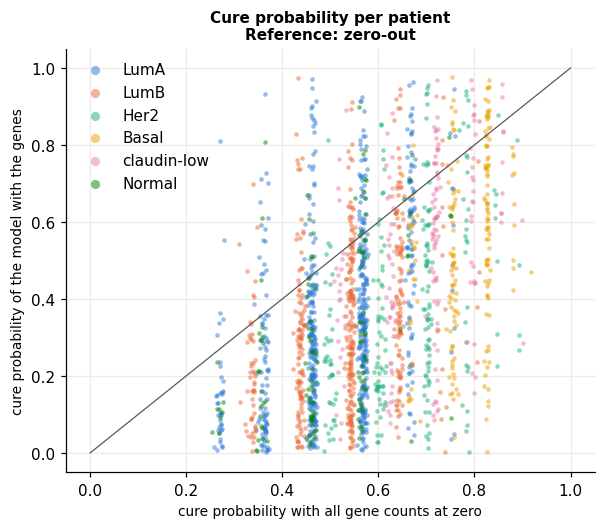

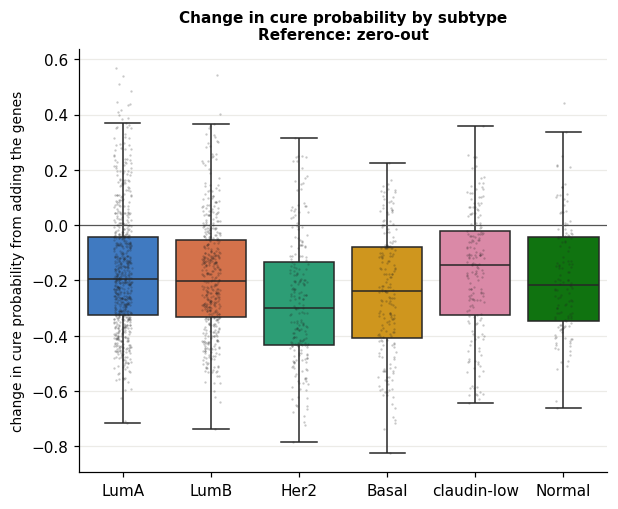

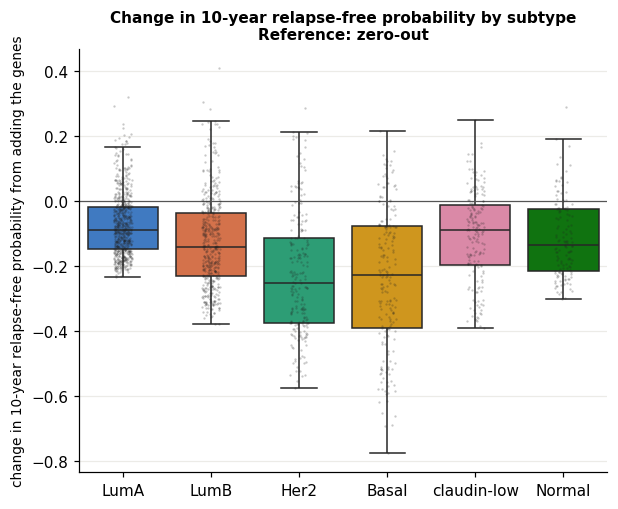

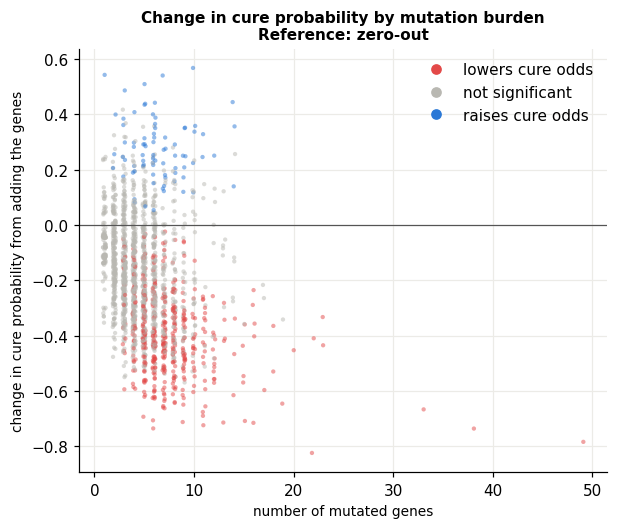

In [3]:
AXIS_NAME = {"zero-out": "with all gene counts at zero", "Structure 1": "from Structure 1 (no genes)"}

def effect_table(ref):
    effect = pd.DataFrame({
        "subtype": subtype.to_numpy(), "n_mutated": n_mutated.to_numpy(), "direction": GENE["direction"].to_numpy(),
        "p_with": WITH["p_test"], "p_without": ref["p_test"],
        "S10_with": survival_at(WITH, 10), "S10_without": survival_at(ref, 10),
    })
    effect["d_p"] = effect["p_with"] - effect["p_without"]
    effect["d_S10"] = effect["S10_with"] - effect["S10_without"]
    return effect

def effect_figures(name):
    effect, axis = effect_table(REFERENCES[name]), AXIS_NAME[name]
    title = f"Reference: {name}"

    fig, ax = plt.subplots(figsize = (6.2, 5))
    for s in SUBTYPES:
        d = effect[effect["subtype"] == s]
        ax.scatter(d["p_without"], d["p_with"], s = 9, alpha = 0.5, color = SUBTYPE_COLOR[s], label = s, lw = 0)
    ax.plot([0, 1], [0, 1], color = "#555555", lw = 0.8)
    ax.set_xlabel(f"cure probability {axis}")
    ax.set_ylabel("cure probability of the model with the genes")
    ax.set_title(f"Cure probability per patient\n{title}")
    ax.legend(markerscale = 2)
    plt.show()

    for col, label, what in [("d_p", "change in cure probability from adding the genes", "Change in cure probability by subtype"),
                             ("d_S10", "change in 10-year relapse-free probability from adding the genes", "Change in 10-year relapse-free probability by subtype")]:
        fig, ax = plt.subplots(figsize = (6.2, 5))
        sns.boxplot(data = effect, x = "subtype", y = col, order = SUBTYPES, hue = "subtype", palette = SUBTYPE_COLOR, legend = False, showfliers = False, linewidth = 1, ax = ax)
        sns.stripplot(data = effect, x = "subtype", y = col, order = SUBTYPES, color = "#222222", size = 1.5, alpha = 0.25, ax = ax)
        ax.axhline(0, color = "#555555", lw = 0.8)
        ax.set_xlabel("")
        ax.set_ylabel(label)
        ax.set_title(f"{what}\n{title}")
        plt.show()

    fig, ax = plt.subplots(figsize = (6.2, 5))
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(effect))
    ax.scatter(effect["n_mutated"] + jitter, effect["d_p"], s = 8, alpha = 0.5, c = effect["direction"].map(DIRECTION_COLOR), lw = 0)
    ax.axhline(0, color = "#555555", lw = 0.8)
    ax.set_xlabel("number of mutated genes")
    ax.set_ylabel("change in cure probability from adding the genes")
    ax.set_title(f"Change in cure probability by mutation burden\n{title}")
    ax.legend(handles = [Line2D([], [], marker = "o", ls = "", color = c, label = d) for d, c in DIRECTION_COLOR.items()], loc = "upper right")
    plt.show()
    return effect

effect = effect_figures("zero-out")

### 1.2 Structure 3 against Structure 1

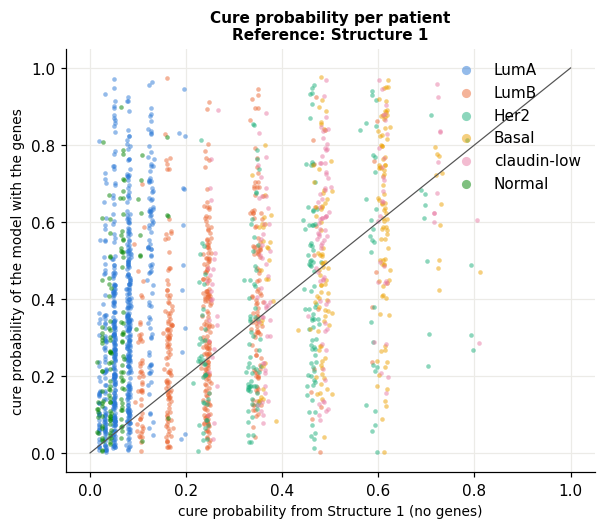

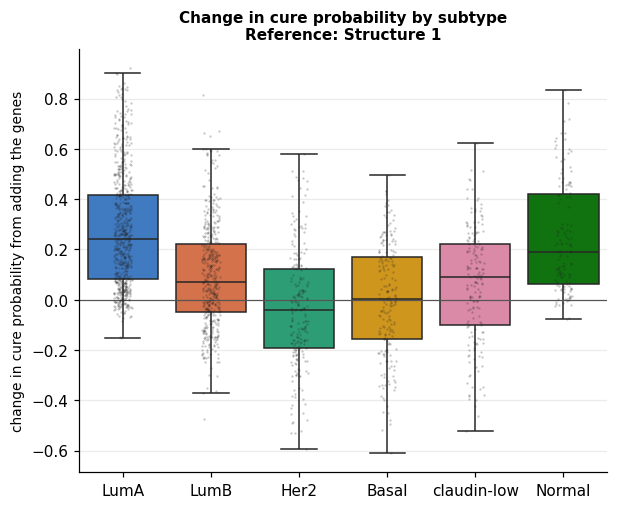

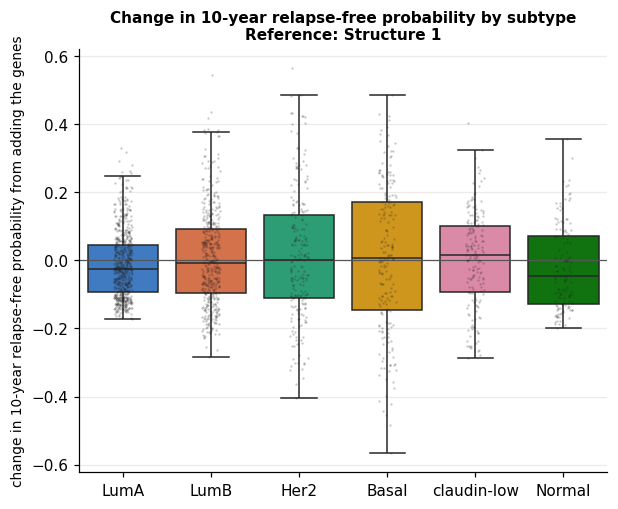

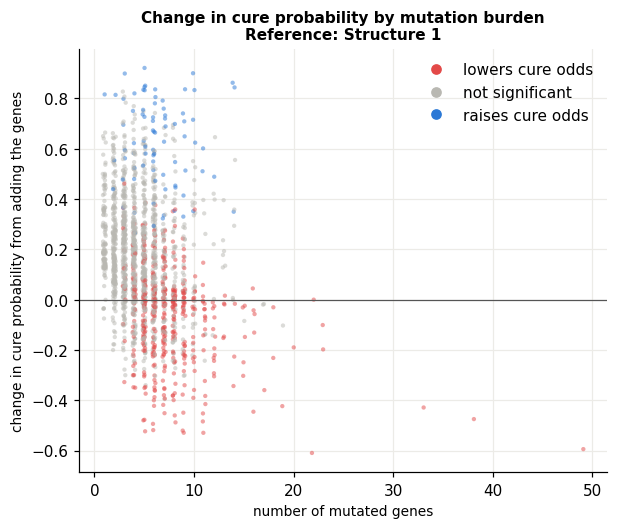

In [4]:
effect = effect_figures("Structure 1")

## 2. Shapley values of `p_nn`

Kernel SHAP on the network output (the cure logit contribution of the genes), explained for all 1,849 patients against a background of 100 k-means centers of the gene profiles. A positive value means the gene raises the cure logit of that patient relative to the average profile. The graphs keep the ten genes with the largest mean |Shapley value|, and `n` in the labels is the number of patients with the gene mutated. The values are cached.

Correlation between the summed Shapley values and p_nn: 0.830


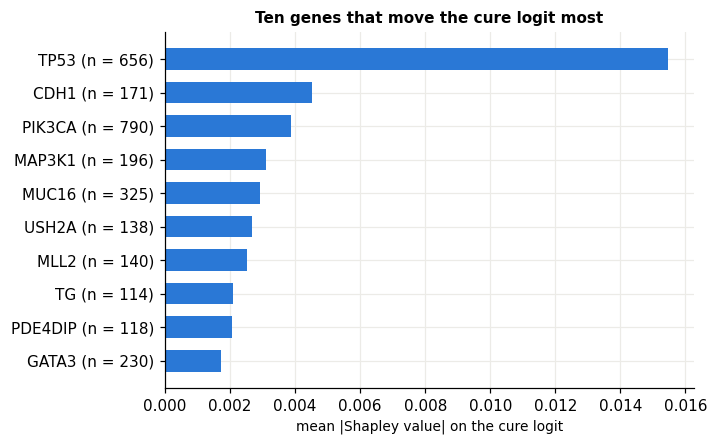

/tmp/ipykernel_864982/2464496757.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:, columns], X.iloc[:, columns], feature_names = list(labels[top.index]), max_display = 10, show = False)


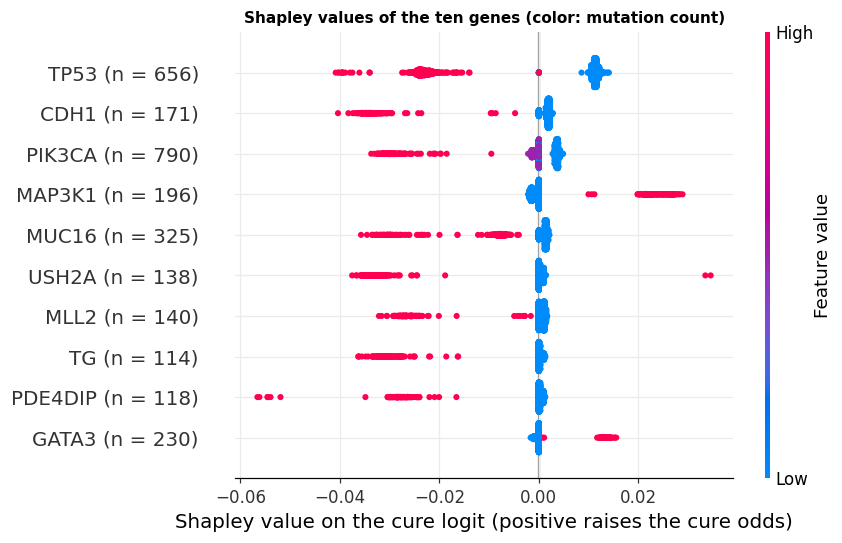

In [5]:
import shap

BACKGROUND_SIZE = 100
shap_path = CACHE_DIR / f"shap_all_bg{BACKGROUND_SIZE}.npy"
genes = np.array(X.columns)
if shap_path.exists():
    shap_values = np.load(shap_path)
else:
    background = shap.kmeans(X.to_numpy(), BACKGROUND_SIZE)
    nn_logit = lambda x: cure_aft.network_call(model3, tf.cast(x, tf.float32), training = False).numpy().ravel()
    shap_values = shap.KernelExplainer(nn_logit, background).shap_values(X.to_numpy())
    np.save(shap_path, shap_values)
assert shap_values.shape == X.shape

carriers = (X > 0).sum()
labels = pd.Series([f"{g} (n = {carriers[g]})" for g in genes], index = genes)
importance = pd.Series(np.abs(shap_values).mean(axis = 0), index = genes).sort_values(ascending = False)
top = importance.head(10)
columns = [list(genes).index(g) for g in top.index]
print(f"Correlation between the summed Shapley values and p_nn: {np.corrcoef(shap_values.sum(axis = 1), GENE['p_nn'])[0, 1]:.3f}")

fig, ax = plt.subplots(figsize = (6.2, 4.2))
ax.barh(labels[top.index][::-1], top.values[::-1], color = POS, height = 0.65)
ax.set_xlabel("mean |Shapley value| on the cure logit")
ax.set_title("Ten genes that move the cure logit most")
plt.show()

shap.summary_plot(shap_values[:, columns], X.iloc[:, columns], feature_names = list(labels[top.index]), max_display = 10, show = False)
plt.gcf().set_size_inches(8, 4.8)
plt.title("Shapley values of the ten genes (color: mutation count)")
plt.xlabel("Shapley value on the cure logit (positive raises the cure odds)")
plt.show()

## 3. t-SNE of the patients with a significant gene effect

Two views of all patients: the raw mutation profile (Jaccard distance on mutated yes/no) and the 16-unit layer of the network before its output. Gray points are the patients whose gene effect is not significant. Colored points are the significant ones.

/home/tonso/code/nhilariosilva/metabric_aft_models/venv/lib/python3.12/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


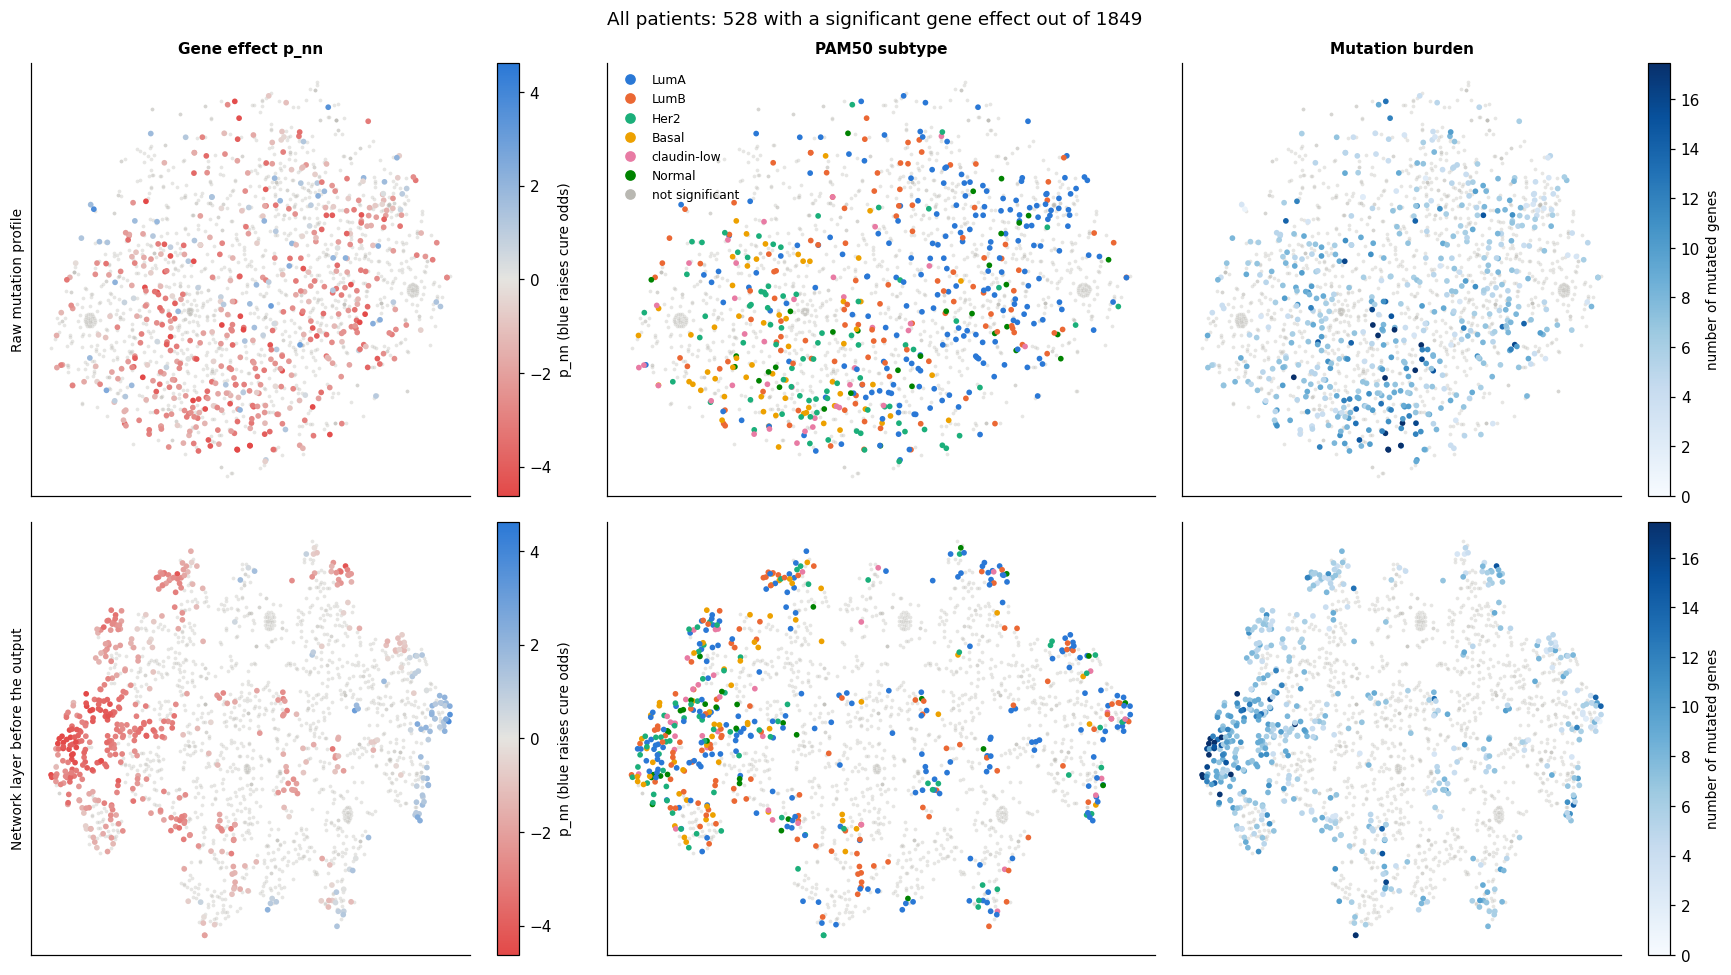

In [6]:
sig = GENE["significant"].to_numpy()
embeddings = {
    "Raw mutation profile": TSNE(perplexity = 30, metric = "jaccard", init = "random", random_state = 0).fit_transform((X > 0).to_numpy()),
    "Network layer before the output": TSNE(perplexity = 30, random_state = 0).fit_transform(
        cure_aft.network_call_nolast(model3, tf.cast(X, tf.float32), training = False).numpy()),
}

def scatter_embedding(ax, emb, color, **kw):
    ax.scatter(*emb[~sig].T, s = 6, color = NS, alpha = 0.35, lw = 0)
    return ax.scatter(*emb[sig].T, s = 14, c = color, lw = 0, **kw)

p_nn = GENE["p_nn"].to_numpy()
limit = np.percentile(np.abs(p_nn[sig]), 98)
burden = n_mutated.to_numpy()

fig, ax = plt.subplots(2, 3, figsize = (16, 9))
for row, (name, emb) in enumerate(embeddings.items()):
    sc = scatter_embedding(ax[row, 0], emb[:, :2], p_nn[sig], cmap = DIVERGING, norm = TwoSlopeNorm(0, -limit, limit))
    fig.colorbar(sc, ax = ax[row, 0], label = "p_nn (blue raises cure odds)")
    scatter_embedding(ax[row, 1], emb[:, :2], subtype[sig].map(SUBTYPE_COLOR).to_numpy())
    sc = scatter_embedding(ax[row, 2], emb[:, :2], burden[sig], cmap = "Blues", vmin = 0, vmax = np.percentile(burden[sig], 98))
    fig.colorbar(sc, ax = ax[row, 2], label = "number of mutated genes")
    ax[row, 0].set_ylabel(name)
    for a in ax[row]:
        a.set(xticks = [], yticks = [])
        a.grid(False)
ax[0, 0].set_title("Gene effect p_nn")
ax[0, 1].set_title("PAM50 subtype")
ax[0, 2].set_title("Mutation burden")
ax[0, 1].legend(handles = [Line2D([], [], marker = "o", ls = "", color = c, label = k) for k, c in SUBTYPE_COLOR.items()]
                + [Line2D([], [], marker = "o", ls = "", color = NS, label = "not significant")], loc = "best", fontsize = 8)
fig.suptitle(f"All patients: {sig.sum()} with a significant gene effect out of {len(sig)}")
fig.tight_layout()
plt.show()